In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Dataset/OnlineRetail.csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Matplotlib is building the font cache; this may take a moment.


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
#check dataset information

print("Dataset Shape:",df.shape)
print("\nColumn Information:")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nNegative or Zero Quantities:")
print((df['Quantity'] <= 0).sum())
print("\nNegative or Zero Prices:")
print((df['UnitPrice'] <= 0).sum())
print("\nSample Invoice Numbers:")
print(df["InvoiceNo"].head(10))

Dataset Shape: (541909, 8)

Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB
None

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268

Negative or Zero Quantities:
10624

Negative or Zero Prices:
2517

Sample Invoice Numbers:
0    536365
1    536365
2    536365
3  

In [5]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove rows with missing CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

# Convert InvoiceDate to datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Remove rows with invalid dates
df_clean = df_clean.dropna(subset=["InvoiceDate"])

# Calculate total amount for each transaction line
df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)
print("\nRemaining Missing Values:")
print(df_clean.isnull().sum())


Original Dataset Shape: (541909, 8)
Cleaned Dataset Shape: (392692, 9)

Remaining Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64


In [6]:

print(df_clean.head())

print("\nUnique Customers:", df_clean["CustomerID"].nunique())

print("\nDate Range:")
print("Start:", df_clean["InvoiceDate"].min())
print("End:", df_clean["InvoiceDate"].max())

print("\nTotal Revenue:", round(df_clean["TotalAmount"].sum(), 2))


  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalAmount  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom        15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom        22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom        20.34  

Unique Customers: 4338

Date Range:
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00

Total Revenue: 888720

In [7]:
# Set reference date one day after the last transaction
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM values for each customer
rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
)

# Display RFM table
print("RFM Dataset Shape:", rfm.shape)
print("\nFirst 5 Customers:")
print(rfm.head())

print("\nRFM Statistics:")
print(rfm.describe())


RFM Dataset Shape: (4338, 3)

First 5 Customers:
            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40

RFM Statistics:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


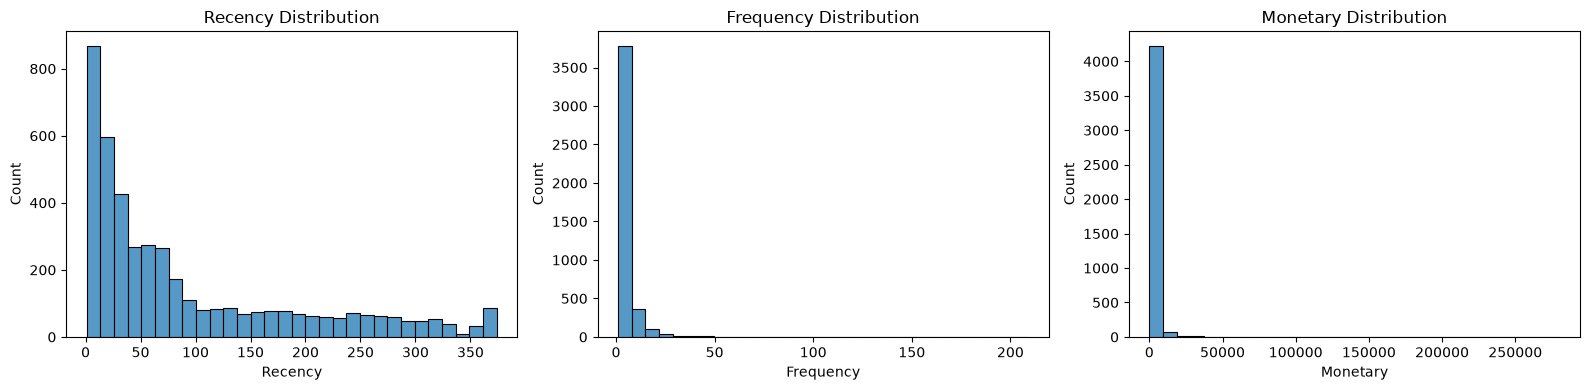

In [8]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(rfm["Recency"], bins=30, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm["Frequency"], bins=30, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(rfm["Monetary"], bins=30, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()


In [9]:

from sklearn.preprocessing import StandardScaler

# Select RFM features
X = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Apply log transformation to reduce skewness
X_log = np.log1p(X)

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Scaled RFM Shape:", X_scaled.shape)
print("\nFirst 5 Scaled Rows:")
print(X_scaled[:5])


Scaled RFM Shape: (4338, 3)

First 5 Scaled Rows:
[[ 1.46199281 -0.95521426  3.7077163 ]
 [-2.03873442  1.07442519  1.41490344]
 [ 0.37310424  0.38630445  0.72002428]
 [-0.62308592 -0.95521426  0.70228691]
 [ 1.42455753 -0.95521426 -0.61451388]]


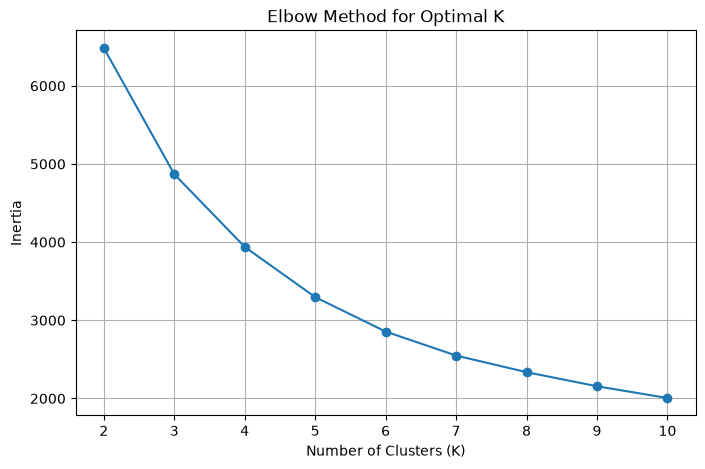

In [10]:

from sklearn.cluster import KMeans

inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


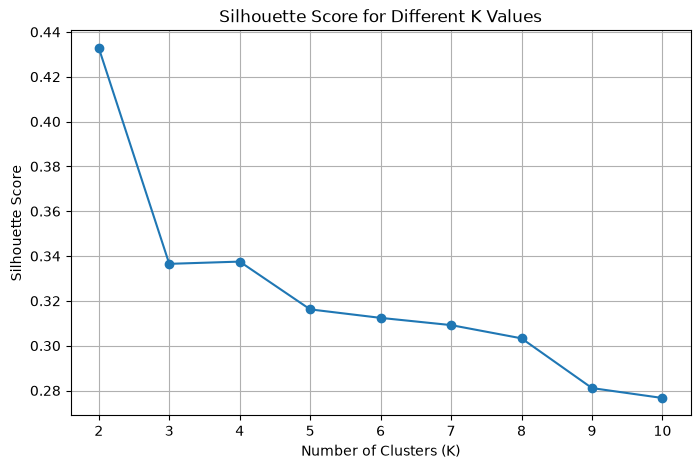

K=2: Silhouette Score=0.4328
K=3: Silhouette Score=0.3365
K=4: Silhouette Score=0.3375
K=5: Silhouette Score=0.3162
K=6: Silhouette Score=0.3124
K=7: Silhouette Score=0.3092
K=8: Silhouette Score=0.3033
K=9: Silhouette Score=0.2811
K=10: Silhouette Score=0.2767


In [11]:

from sklearn.metrics import silhouette_score

silhouette_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

for k, score in zip(range(2, 11), silhouette_values):
    print(f"K={k}: Silhouette Score={score:.4f}")


In [12]:
# Apply K-Means with the selected K
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster Distribution:")
print(rfm["KMeans_Cluster"].value_counts().sort_index())

print("\nRFM Summary by Cluster:")
print(
    rfm.groupby("KMeans_Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ].mean().round(2)
)


Cluster Distribution:
KMeans_Cluster
0    2672
1    1666
Name: count, dtype: int64

RFM Summary by Cluster:
                Recency  Frequency  Monetary
KMeans_Cluster                              
0                134.09       1.67    495.59
1                 25.89       8.44   4539.60


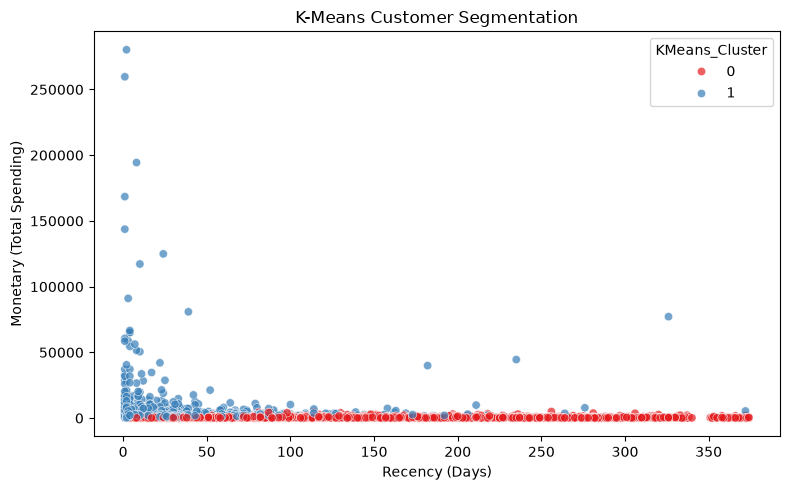

In [13]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="KMeans_Cluster",
    palette="Set1",
    alpha=0.7
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary (Total Spending)")
plt.tight_layout()
plt.show()


In [14]:
#dbscan clustering

from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=10
)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print("DBSCAN Cluster Distribution:")
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

n_clusters = len(set(rfm["DBSCAN_Cluster"])) - (
    1 if -1 in rfm["DBSCAN_Cluster"].values else 0
)

n_noise = (rfm["DBSCAN_Cluster"] == -1).sum()

print("\nNumber of DBSCAN Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)


DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1      79
 0    2780
 1    1479
Name: count, dtype: int64

Number of DBSCAN Clusters: 2
Number of Noise Points: 79


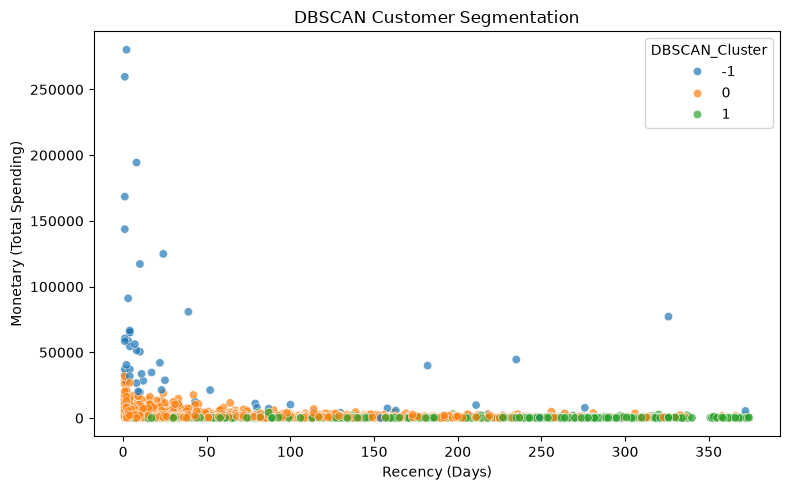

In [15]:
#dbscan visualization

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="DBSCAN_Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("DBSCAN Customer Segmentation")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary (Total Spending)")
plt.tight_layout()
plt.show()


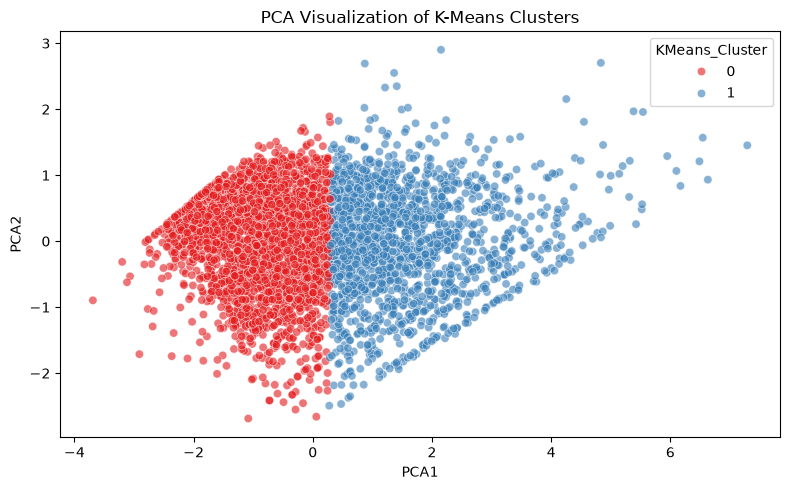

Explained Variance Ratio: [0.75078634 0.18786648]
Total Variance Explained: 0.9387


In [16]:
#pca visualization
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({"PCA1": X_pca[:, 0], "PCA2": X_pca[:, 1], "KMeans_Cluster": rfm["KMeans_Cluster"]})
plt.figure(figsize=(8, 5))
sns.scatterplot(data=pca_df, x="PCA1", y="PCA2", hue="KMeans_Cluster", palette="Set1", alpha=0.6)
plt.title("PCA Visualization of K-Means Clusters")
plt.tight_layout()
plt.show()
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Explained:",round(pca.explained_variance_ratio_.sum(),4))

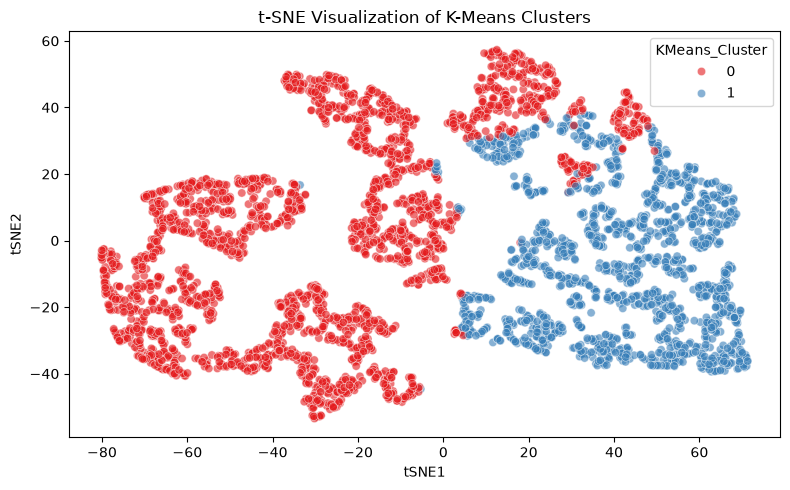

In [18]:

from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame({
    "tSNE1": X_tsne[:, 0],
    "tSNE2": X_tsne[:, 1],
    "KMeans_Cluster": rfm["KMeans_Cluster"].values
})

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=tsne_df,
    x="tSNE1",
    y="tSNE2",
    hue="KMeans_Cluster",
    palette="Set1",
    alpha=0.6
)

plt.title("t-SNE Visualization of K-Means Clusters")
plt.tight_layout()
plt.show()


In [19]:
#marketing personas

cluster_summary = rfm.groupby("KMeans_Cluster").agg(
    Customer_Count=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customer_Count"] / len(rfm) * 100
).round(2)

print(cluster_summary)


                Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary  \
KMeans_Cluster                                                             
0                         2672       134.09           1.67        495.59   
1                         1666        25.89           8.44       4539.60   

                Customer_Percentage  
KMeans_Cluster                       
0                              61.6  
1                              38.4  


In [20]:

from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

# Save cluster results
rfm.to_csv(results_dir / "customer_segments.csv")
cluster_summary.to_csv(results_dir / "cluster_summary.csv")

# Save visualizations
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=pca_df, x="PCA1", y="PCA2",
    hue="KMeans_Cluster", palette="Set1", alpha=0.6, ax=ax
)
ax.set_title("PCA Customer Segments")
fig.tight_layout()
fig.savefig(results_dir / "pca_clusters.png", dpi=150)
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=tsne_df, x="tSNE1", y="tSNE2",
    hue="KMeans_Cluster", palette="Set1", alpha=0.6, ax=ax
)
ax.set_title("t-SNE Customer Segments")
fig.tight_layout()
fig.savefig(results_dir / "tsne_clusters.png", dpi=150)
plt.close(fig)

print("Results saved successfully!")


Results saved successfully!


In [21]:

# Compare both clustering algorithms

print("K-MEANS RESULTS")
print("-" * 30)
print(rfm["KMeans_Cluster"].value_counts().sort_index())

print("\nDBSCAN RESULTS")
print("-" * 30)
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

print("\nCOMPARISON SUMMARY")
print("-" * 30)

kmeans_clusters = rfm["KMeans_Cluster"].nunique()

dbscan_clusters = rfm["DBSCAN_Cluster"].nunique()
if -1 in rfm["DBSCAN_Cluster"].unique():
    dbscan_clusters -= 1

dbscan_noise = (rfm["DBSCAN_Cluster"] == -1).sum()

print("K-Means clusters:", kmeans_clusters)
print("DBSCAN clusters:", dbscan_clusters)
print("DBSCAN noise points:", dbscan_noise)


K-MEANS RESULTS
------------------------------
KMeans_Cluster
0    2672
1    1666
Name: count, dtype: int64

DBSCAN RESULTS
------------------------------
DBSCAN_Cluster
-1      79
 0    2780
 1    1479
Name: count, dtype: int64

COMPARISON SUMMARY
------------------------------
K-Means clusters: 2
DBSCAN clusters: 2
DBSCAN noise points: 79
